# Merging and Joining DataFrames in Pandas

Data comes from several sources: trips from one system, zone names from another, February in a second file. **Merging** matches rows by keys (like SQL joins, M07 L05); **concatenation** stacks tables. The main risks are silent: lost rows, duplicated rows and unmatched keys.

**After this lesson you can:**

1. Merge with `inner`, `left`, `right` and `outer` joins, also on two different key columns.
2. Validate key relationships (`validate=`) and find unmatched rows (`indicator=True`).
3. Concatenate tables of the same structure.
4. Match rows to the nearest earlier timestamp with `merge_asof`.

**Data:** NYC yellow taxi trips (January and February 2024) and the taxi zone lookup table.

In [1]:
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.insert(0, str(Path.cwd().parent / "tools"))
import datasets                                   # course helper: downloads pinned public datasets

COLS = ["tpep_pickup_datetime", "tpep_dropoff_datetime", "passenger_count", "trip_distance", "PULocationID", "DOLocationID", "payment_type", "fare_amount", "tip_amount", "total_amount"]
raw = pd.read_parquet(datasets.taxi("2024-01"), columns=COLS)        # NYC yellow taxi trips, January 2024
zones = pd.read_csv(datasets.fetch("taxi_zone_lookup.csv"))

def clean_trips(df: pd.DataFrame) -> pd.DataFrame:
    """The cleaning rules of Lesson 08 in one function."""
    duration = (df["tpep_dropoff_datetime"] - df["tpep_pickup_datetime"]).dt.total_seconds() / 60
    ok = (df["tpep_pickup_datetime"].between("2024-01-01", "2024-02-01", inclusive="left")
          & duration.between(1, 180) & df["trip_distance"].between(0.1, 100)
          & df["fare_amount"].between(3, 500) & (df["total_amount"] > 0))
    return df[ok].assign(duration_min=duration[ok])

trips = clean_trips(raw)
print(f"{len(raw):,} raw trips -> {len(trips):,} clean trips")

2,964,624 raw trips -> 2,855,769 clean trips


## 1. Merge Trips with Zone Names

Each trip has a pickup and a drop-off zone id. The zone table has one row per id. Merging twice adds both names; `suffixes` distinguishes the two sets of columns.

In [2]:
zones_small = zones[["LocationID", "Borough", "Zone"]]
named = (trips
         .merge(zones_small, left_on="PULocationID", right_on="LocationID", how="left", validate="m:1")
         .merge(zones_small, left_on="DOLocationID", right_on="LocationID", how="left", validate="m:1",
                suffixes=("_pickup", "_dropoff"))
         .drop(columns=["LocationID_pickup", "LocationID_dropoff"]))
print(f"rows before {len(trips):,} | after {len(named):,} (a left join on a unique key keeps the row count)")
named[["Zone_pickup", "Borough_pickup", "Zone_dropoff", "Borough_dropoff", "fare_amount"]].head()

rows before 2,855,769 | after 2,855,769 (a left join on a unique key keeps the row count)


,Zone_pickup,Borough_pickup,Zone_dropoff,Borough_dropoff,fare_amount
0,Penn Station/Madison Sq West,Manhattan,East Village,Manhattan,17.7
1,Lenox Hill East,Manhattan,Upper East Side North,Manhattan,10.0
2,Upper East Side North,Manhattan,East Village,Manhattan,23.3
3,East Village,Manhattan,SoHo,Manhattan,10.0
4,SoHo,Manhattan,Lower East Side,Manhattan,7.9


`validate="m:1"` checks that the right table has **unique** keys. If the zone table contained a duplicate id, pandas would raise an error instead of silently duplicating trips.

## 2. Join Types and Unmatched Keys

`indicator=True` adds a column `_merge` with `left_only`, `right_only` or `both`. It is the fastest way to audit a merge.

In [3]:
pickup_counts = trips.groupby("PULocationID").size().rename("trips").reset_index()
audit = zones_small.merge(pickup_counts, left_on="LocationID", right_on="PULocationID", how="outer", indicator=True)
print(audit["_merge"].value_counts(), "\n")
print("zones without any pickup in January:")
print(audit.loc[audit["_merge"] == "left_only", ["LocationID", "Borough", "Zone"]].to_string(index=False))

sizes = {how: len(zones_small.merge(pickup_counts, left_on="LocationID", right_on="PULocationID", how=how))
         for how in ["inner", "left", "right", "outer"]}
print("\nrows per join type:", sizes)

_merge
both          256
left_only       9
right_only      0
Name: count, dtype: int64 

zones without any pickup in January:
 LocationID       Borough                                          Zone
          5 Staten Island                                 Arden Heights
         84 Staten Island             Eltingville/Annadale/Prince's Bay
         99 Staten Island                               Freshkills Park
        103     Manhattan Governor's Island/Ellis Island/Liberty Island
        104     Manhattan Governor's Island/Ellis Island/Liberty Island
        110 Staten Island                              Great Kills Park
        111      Brooklyn                           Green-Wood Cemetery
        187 Staten Island                                 Port Richmond
        221 Staten Island                                     Stapleton



rows per join type: {'inner': 256, 'left': 265, 'right': 256, 'outer': 265}


## 3. The Many-to-Many Trap

If **both** tables have repeated keys, a merge returns every combination: the number of rows can explode. The cell merges two trip tables on the pickup zone alone.

In [4]:
a = trips.head(2000)[["PULocationID", "fare_amount"]]
b = trips.iloc[2000:4000][["PULocationID", "tip_amount"]]
exploded = a.merge(b, on="PULocationID")
print(f"{len(a):,} rows x {len(b):,} rows -> {len(exploded):,} rows after a many-to-many merge")
try:
    a.merge(b, on="PULocationID", validate="one_to_many")
except pd.errors.MergeError as err:
    print("validate caught it:", str(err)[:80])

2,000 rows x 2,000 rows -> 111,242 rows after a many-to-many merge
validate caught it: Merge keys are not unique in left dataset; not a one-to-many merge
Duplicates in


## 4. Concatenate Months

`pd.concat` stacks DataFrames with the same columns. `keys=` adds a level that records the source of each row.

In [5]:
feb = pd.read_parquet(datasets.taxi("2024-02"), columns=COLS)
both = pd.concat([raw, feb], keys=["2024-01", "2024-02"], names=["file", "row"])
print(f"January {len(raw):,} + February {len(feb):,} = {len(both):,} rows")
per_file = both.groupby(level="file").agg(trips=("fare_amount", "size"), median_fare=("fare_amount", "median"))
per_file

January 2,964,624 + February 3,007,526 = 5,972,150 rows


,trips,median_fare
file,,
2024-01,2964624,12.8
2024-02,3007526,12.8


## 5. `merge_asof`: Nearest Earlier Match

Some data must be matched by **time**, not by equal keys: each trade with the latest price, each sensor reading with the latest calibration. `merge_asof` matches each left row with the last right row whose key is **less than or equal**. Both tables must be sorted by the key.

The example builds an hourly demand table (trips started in the previous full hour) and attaches it to each trip, a typical feature for a fare or wait-time model.

In [6]:
hourly = (trips.set_index("tpep_pickup_datetime").resample("h").size().rename("trips_last_hour")
          .reset_index().rename(columns={"tpep_pickup_datetime": "hour_start"}))
hourly["available_at"] = hourly["hour_start"] + pd.Timedelta(hours=1)        # a count is known only after its hour ends

sample = trips.sample(20_000, random_state=0).sort_values("tpep_pickup_datetime")
with_demand = pd.merge_asof(sample, hourly[["available_at", "trips_last_hour"]].sort_values("available_at"),
                            left_on="tpep_pickup_datetime", right_on="available_at", direction="backward")
print(with_demand[["tpep_pickup_datetime", "available_at", "trips_last_hour"]].head(4))
unmatched = with_demand["available_at"].isna()
print(f"\ntrips in the first hour have no earlier count: {unmatched.sum()} (NaN, as intended)")
print("no future information used:", (with_demand.loc[~unmatched, "available_at"] <= with_demand.loc[~unmatched, "tpep_pickup_datetime"]).all())

  tpep_pickup_datetime available_at  trips_last_hour
0  2024-01-01 00:03:26          NaT              NaN
1  2024-01-01 00:05:04          NaT              NaN
2  2024-01-01 00:05:57          NaT              NaN
3  2024-01-01 00:07:20          NaT              NaN

trips in the first hour have no earlier count: 42 (NaN, as intended)
no future information used: True


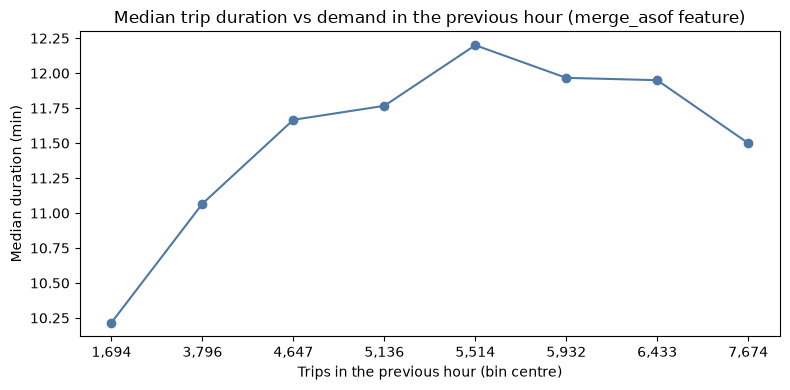

In [7]:
fig, ax = plt.subplots(figsize=(8, 4))
binned = with_demand.groupby(pd.qcut(with_demand["trips_last_hour"], 8), observed=True)["duration_min"].median()
ax.plot([f"{iv.mid:,.0f}" for iv in binned.index], binned.values, marker="o", color="#4E79A7")
ax.set(title="Median trip duration vs demand in the previous hour (merge_asof feature)",
       xlabel="Trips in the previous hour (bin centre)", ylabel="Median duration (min)")
plt.tight_layout()
plt.show()

Trips get longer as the previous hour gets busier (traffic), up to about 5,500 trips per hour; in the very busiest hours, trips are slightly shorter again. Using `available_at` instead of `hour_start` avoids **data leakage**: a model must not see information from the future (M16).

*Insight: Audit every merge: check the row count before and after, use `validate=` to enforce the key relationship, and use `indicator=True` to see unmatched keys. Most wrong numbers in reports come from a silent merge problem.*

## Real-World Use Case or Analogy

Merging is like **combining a guest list with a seating plan**: each guest (trip) gets the table name (zone) by number. If the seating plan accidentally lists table 7 twice, some guests get two seats (`validate` catches this); guests whose table number is not in the plan end up without a seat (`indicator` shows them).

Financial data teams use `merge_asof` to join trades with quotes; marketing teams join orders with the last campaign a customer saw; ML teams build point-in-time correct features this way (feature stores, M34).